In [1]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
from scipy.linalg import cholesky, solve_triangular, svd
import matplotlib.pyplot as plt
import time

from KRR_utils import *
from nystrom_functions import *

In [3]:
rng = np.random.default_rng(0)
n = 200
r = 100
X = rng.standard_normal((n, r))
A = X @ X.T
k = 50
l = 100
U, lam, Ahat = random_nystrom(A, k, l, rng)
err_2 = np.linalg.norm(A - Ahat, ord="fro")
rank_Ahat = np.linalg.matrix_rank(Ahat)

print("Approximate rank:", rank_Ahat)
print("Frobenius error:", err_2)

Approximate rank: 50
Frobenius error: 662.6722186782221



kernel = linear
full krr mse = 2.855664412221671
full krr runtime = 0.0637737000361085

l = 1
uniform mse = 235801169.5826949
uniform forward error = 0.940683725574445
uniform runtime = 0.09568520006723702
gaussian mse = 258639658.59352893
gaussian forward error = 0.940057091189982
gaussian runtime = 0.14492890005931258

l = 6
uniform mse = 135442423.96381295
uniform forward error = 0.6214674792340499
uniform runtime = 0.06458480004221201
gaussian mse = 211953975.42906737
gaussian forward error = 0.6054208274446959
gaussian runtime = 0.02848379989154637

l = 11
uniform mse = 2.8556644122415467
uniform forward error = 3.241158284175983e-15
uniform runtime = 0.04856999986805022
gaussian mse = 2.85566440376992
gaussian forward error = 5.1255075871076755e-09
gaussian runtime = 0.044646100141108036

l = 16
uniform mse = 2.855664412232648
uniform forward error = 1.3290565768787763e-15
uniform runtime = 0.01847529993392527
gaussian mse = 2.855664409988498
gaussian forward error = 4.415384875

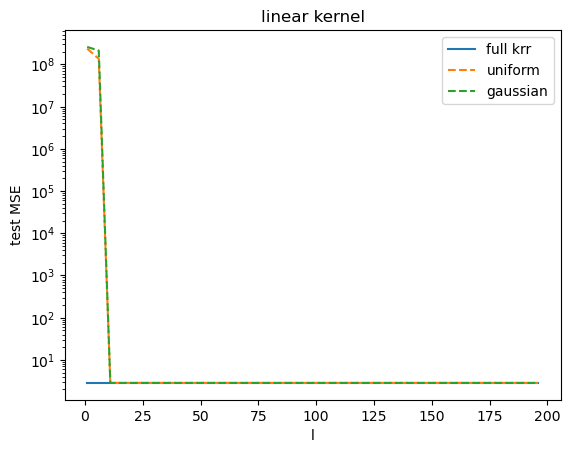

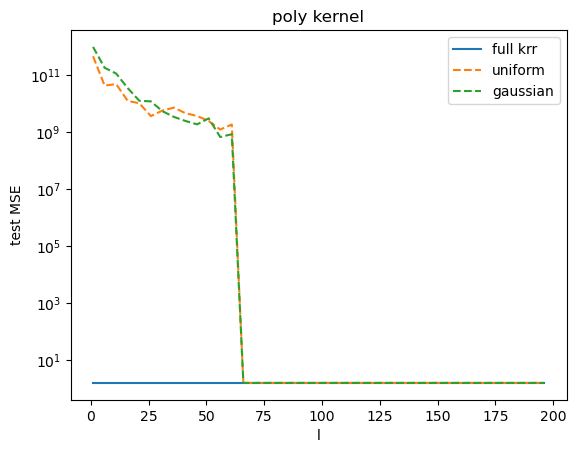

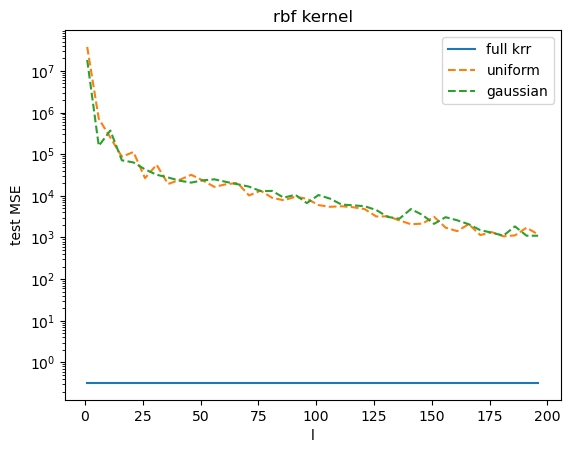

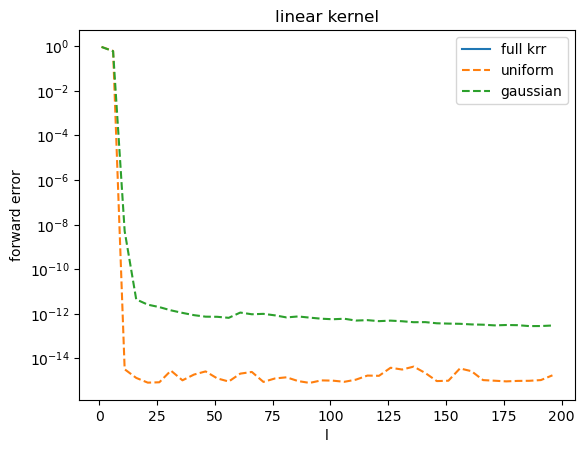

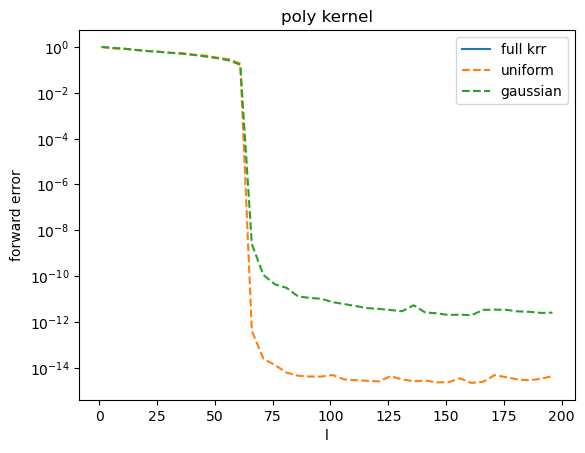

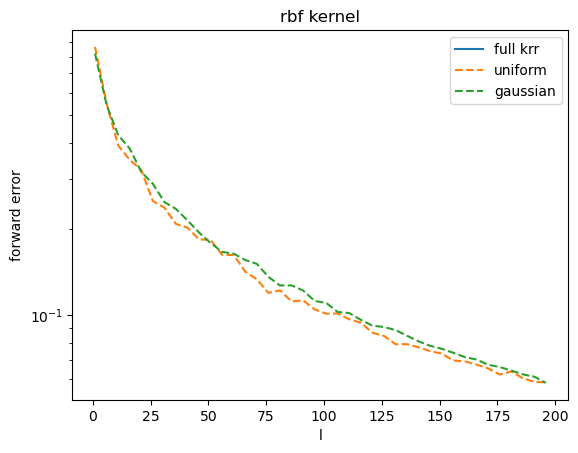

In [19]:
rng = np.random.default_rng(0)

n = 1000
d = 10
lam = 1e-2
noiselevel = 1e-3

X = rng.standard_normal((n,d))
y_true = X[:,0]*X[:,1]*X[:,8] + np.exp(-X[:,2]**2) + np.sin(np.sum(X[:,3:7]))
noise = noiselevel*rng.standard_normal(n)
y = y_true + noise

ind = rng.permutation(n)

n_train = 800
train_ind = ind[:n_train]
test_ind = ind[n_train:]
X_train = X[train_ind]
y_train = y[train_ind]
X_test = X[test_ind]
y_test = y[test_ind]

def get_error(y_test,y_hat): #mse
    err = np.mean((y_test-y_hat)**2)
    return err


kernel_names = ["linear","poly","rbf"]
kernel_list = [linear,poly,rbf]
l_values = range(1, 200, 5)
results = []

for a in range(len(kernel_list)):
    name = kernel_names[a]
    kernel = kernel_list[a]
    print("")
    print("kernel =",name)

    t0 = time.perf_counter()

    K_train = kernel(X_train,X_train)
    K_test = kernel(X_test,X_train)
    alpha = np.linalg.solve(K_train + lam*np.eye(n_train),y_train) #full krr
    y_hat = K_test @ alpha
    full_time = time.perf_counter() - t0
    full_mse = get_error(y_test,y_hat)

    print("full krr mse =",full_mse)
    print("full krr runtime =",full_time)

    for l in l_values:
        print("")
        print("l =",l)

        t0 = time.perf_counter()

        sample_ind = rng.choice(n_train,size=l,replace=False) #random uniform
        C = K_train[:,sample_ind]
        W = K_train[sample_ind, :]
        W = W[:, sample_ind]
        K_uni = C @ np.linalg.pinv(W) @ C.T
        alpha_uni = np.linalg.solve(K_uni + lam*np.eye(n_train),y_train)
        y_hat_uni = K_test @ alpha_uni

        uni_time = time.perf_counter() - t0

        uni_mse = get_error(y_test,y_hat_uni)
        uni_fro = np.linalg.norm(K_train-K_uni,ord="fro")/np.linalg.norm(K_train,ord="fro")

        print("uniform mse =",uni_mse)
        print("uniform forward error =",uni_fro)
        print("uniform runtime =",uni_time)

        t0 = time.perf_counter()

        U, eigs, K_gauss = random_nystrom(K_train,l,l,rng) #gaussian method
        alpha_gauss = np.linalg.solve(K_gauss + lam*np.eye(n_train),y_train)
        y_hat_gauss = K_test @ alpha_gauss

        gauss_time = time.perf_counter() - t0

        gauss_mse = get_error(y_test,y_hat_gauss)
        gauss_fro = np.linalg.norm(K_train-K_gauss,ord="fro")/np.linalg.norm(K_train,ord="fro")

        print("gaussian mse =",gauss_mse)
        print("gaussian forward error =",gauss_fro)
        print("gaussian runtime =",gauss_time)

        results.append([name,l,"full",full_mse,0.0,full_time])
        results.append([name,l,"uniform",uni_mse,uni_fro,uni_time])
        results.append([name,l,"gaussian",gauss_mse,gauss_fro,gauss_time])

print("")
print("results")
print("kernel, l, method, mse, forward error, time")
for row in results:
    print(row)

for name in kernel_names:
    l_plot = []
    full_plot = []
    uni_plot = []
    gauss_plot = []

    for row in results:
        if row[0] == name and row[2] == "full":
            l_plot.append(row[1])
            full_plot.append(row[3])
        if row[0] == name and row[2] == "uniform":
            #l_plot.append(row[1])
            uni_plot.append(row[3])
        if row[0] == name and row[2] == "gaussian":
            gauss_plot.append(row[3])

    plt.figure()
    plt.semilogy(l_plot,full_plot,label="full krr")
    plt.semilogy(l_plot,uni_plot,'--',label="uniform")
    plt.semilogy(l_plot,gauss_plot,'--',label="gaussian")
    plt.xlabel("l")
    plt.ylabel("test MSE")
    plt.title(name + " kernel")
    plt.legend()
    plt.show()

for name in kernel_names:

    l_plot = []
    full_plot = []
    uni_plot = []
    gauss_plot = []

    for row in results:
        if row[0] == name and row[2] == "full":
            l_plot.append(row[1])
            full_plot.append(row[4])
        if row[0] == name and row[2] == "uniform":
            #l_plot.append(row[1])
            uni_plot.append(row[4])
        if row[0] == name and row[2] == "gaussian":
            gauss_plot.append(row[4])

    plt.figure()
    plt.semilogy(l_plot,full_plot, label="full krr")
    plt.semilogy(l_plot,uni_plot, '--', label="uniform")
    plt.semilogy(l_plot,gauss_plot,'--',label="gaussian")
    plt.xlabel("l")
    plt.ylabel("forward error")
    plt.title(name + " kernel")
    plt.legend()
    plt.show()

Okay, next we look at ...

<>:37: SyntaxWarning: "\|" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\|"? A raw string is also an option.
<>:37: SyntaxWarning: "\|" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\|"? A raw string is also an option.
C:\Users\P285563\AppData\Local\Temp\ipykernel_66052\172922692.py:37: SyntaxWarning: "\|" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\|"? A raw string is also an option.
  plt.ylabel("$\|K-\hat{k}\|_F/\|K\|_F$")



l = 10
uniform forward error = 0.9000639504751639
gaussian forward error = 0.9091644828516653

l = 50
uniform forward error = 0.5804791694058935
gaussian forward error = 0.578915547129629

l = 100
uniform forward error = 0.2876151915909307
gaussian forward error = 0.30037794062004014

l = 200
uniform forward error = 0.0595299313566412
gaussian forward error = 0.05771906661357622

l = 400
uniform forward error = 0.0012239243058357145
gaussian forward error = 0.0012716876654799072


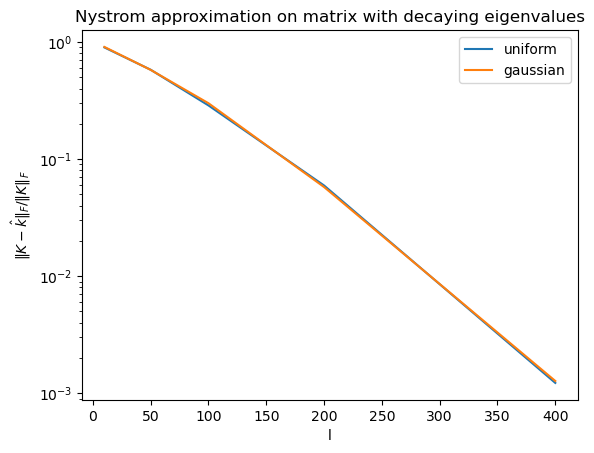

In [13]:
rng = np.random.default_rng(1)
n = 1000
Q, R = np.linalg.qr(rng.standard_normal((n,n)))
eigs = np.logspace(0,-10,n)
A = Q @ np.diag(eigs) @ Q.T

l_values = [10,50,100,200,400]
l_plot = []
uni_plot = []
gauss_plot = []

for l in l_values:

    sample_ind = rng.choice(n,size=l,replace=False)
    C = A[:,sample_ind]
    W = A[sample_ind, :]
    W = W[:, sample_ind]
    A_uni = C @ np.linalg.pinv(W) @ C.T
    U, lam_gauss, A_gauss = random_nystrom(A,l,l,rng)

    uni_err = np.linalg.norm(A-A_uni,ord="fro")/np.linalg.norm(A,ord="fro")
    gauss_err = np.linalg.norm(A-A_gauss,ord="fro")/np.linalg.norm(A,ord="fro")

    print("")
    print("l =",l)
    print("uniform forward error =",uni_err)
    print("gaussian forward error =",gauss_err)

    l_plot.append(l)
    uni_plot.append(uni_err)
    gauss_plot.append(gauss_err)

plt.figure()
plt.semilogy(l_plot,uni_plot,label="uniform")
plt.semilogy(l_plot,gauss_plot,label="gaussian")
plt.xlabel("l")
plt.ylabel("$\|K-\hat{k}\|_F/\|K\|_F$")
plt.title("Nystrom approximation on matrix with decaying eigenvalues")
plt.legend()
plt.show()